In [1]:
# ============================================================
# 07 · Cell 1 — Setup, scikit-learn and data load
# ============================================================
%pip install --quiet scikit-learn

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from commodity_factors.analytics import PerformanceReport, newey_west_tstat
from commodity_factors.config import PATHS

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

FACTORS = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure", "tsmom_12"]


def load(name: str) -> pd.DataFrame:
    return pd.read_parquet(PATHS.processed / f"{name}.parquet")


factor_returns = load("factor_returns_headline")[FACTORS]
combos = load("combination_returns")
benchmarks = load("benchmarks_monthly").loc[: factor_returns.index.max()]
regimes = load("regimes")
macro = pd.read_parquet(PATHS.raw / "fred_macro.parquet")
indices = pd.read_parquet(PATHS.raw / "yahoo_indices.parquet")

print(f"scikit-learn {sklearn.__version__}\n")
for name, frame in {
    "factor_returns": factor_returns, "combos": combos, "benchmarks": benchmarks,
    "regimes": regimes, "macro (FRED)": macro, "indices (DXY)": indices,
}.items():
    valid = frame.dropna(how="all")
    print(f"{name:<15}: {valid.shape[0]:>6,} rows x {valid.shape[1]:>2} cols | "
          f"{valid.index.min():%Y-%m} -> {valid.index.max():%Y-%m}")

print("\nFactor return coverage (first month with data)")
print(factor_returns.apply(lambda s: s.first_valid_index().strftime("%Y-%m")).to_string())

Note: you may need to restart the kernel to use updated packages.
scikit-learn 1.9.1

factor_returns :    296 rows x  6 cols | 2002-02 -> 2026-09
combos         :    272 rows x  3 cols | 2004-02 -> 2026-09
benchmarks     :    321 rows x  6 cols | 2000-01 -> 2026-09
regimes        :    296 rows x  6 cols | 2002-02 -> 2026-09
macro (FRED)   :  8,169 rows x  3 cols | 1995-01 -> 2026-10
indices (DXY)  :  8,070 rows x  1 cols | 1995-01 -> 2026-10

Factor return coverage (first month with data)
mom_12_1            2002-02
carry               2002-02
value               2005-11
skewness            2002-02
hedging_pressure    2002-02
tsmom_12            2002-02


In [2]:
%%writefile src/commodity_factors/ml.py
"""Point-in-time features and targets for timing the six factor portfolios."""

from __future__ import annotations

import numpy as np
import pandas as pd


def compound(returns: pd.Series | pd.DataFrame, window: int):
    """Compounded return over a trailing window (requires a full window)."""
    return np.expm1(np.log1p(returns).rolling(window, min_periods=window).sum())


def month_end(series: pd.Series) -> pd.Series:
    return series.dropna().resample("ME").last()


class FactorFeatureBuilder:
    """Features at month-end t for predicting each factor's return in month t+1.

    Market features (shared by all factors) describe the environment; factor features
    describe each factor's own recent behaviour. Everything uses information available
    at the close of month t; CPI is lagged one extra month for its publication delay.
    """

    MARKET_FEATURES = ["mkt_ret_12m", "mkt_vol_12m", "cpi_yoy", "dxy_chg_12m", "vix"]
    FACTOR_FEATURES = ["ret_1m", "ret_6m", "ret_12m", "vol_12m", "drawdown"]

    def __init__(
        self,
        factor_returns: pd.DataFrame,
        market_returns: pd.Series,
        cpi: pd.Series,
        dxy: pd.Series,
        vix: pd.Series,
    ) -> None:
        self._factors = factor_returns
        self._market = market_returns
        self._cpi, self._dxy, self._vix = cpi, dxy, vix

    def market_features(self) -> pd.DataFrame:
        market = self._market
        frame = pd.DataFrame(
            {
                "mkt_ret_12m": compound(market, 12),
                "mkt_vol_12m": market.rolling(12, min_periods=12).std() * np.sqrt(12),
                "cpi_yoy": month_end(self._cpi).pct_change(12, fill_method=None).shift(1),
                "dxy_chg_12m": month_end(self._dxy).pct_change(12, fill_method=None),
                "vix": month_end(self._vix),
            }
        )
        return frame.reindex(self._factors.index)

    @staticmethod
    def factor_features(returns: pd.Series) -> pd.DataFrame:
        r = returns.dropna()
        wealth = (1 + r).cumprod()
        frame = pd.DataFrame(
            {
                "ret_1m": r,
                "ret_6m": compound(r, 6),
                "ret_12m": compound(r, 12),
                "vol_12m": r.rolling(12, min_periods=12).std() * np.sqrt(12),
                "drawdown": wealth / wealth.cummax() - 1,
            }
        )
        return frame.reindex(returns.index)

    def panel(self) -> pd.DataFrame:
        """Long panel indexed by (date, factor): features plus next-month target return."""
        market = self.market_features()
        target = self._factors.shift(-1)
        frames = []
        for factor in self._factors.columns:
            frame = pd.concat([market, self.factor_features(self._factors[factor])], axis=1)
            frame["target"] = target[factor]
            frame["factor"] = factor
            frames.append(frame)
        panel = pd.concat(frames).rename_axis("date").reset_index()
        return panel.set_index(["date", "factor"]).sort_index()

Writing src/commodity_factors/ml.py


In [3]:
# ============================================================
# 07 · Cell 3 — Build and inspect the feature panel
# ============================================================
from commodity_factors.ml import FactorFeatureBuilder, compound

builder = FactorFeatureBuilder(
    factor_returns=factor_returns,
    market_returns=benchmarks["EW_all"],
    cpi=macro["cpi"],
    dxy=indices["dxy"],
    vix=macro["vix"],
)
panel = builder.panel()
FEATURES = FactorFeatureBuilder.MARKET_FEATURES + FactorFeatureBuilder.FACTOR_FEATURES
complete = panel.dropna(subset=FEATURES + ["target"])

# 1. Coverage
print(f"Panel: {panel.shape[0]:,} rows x {panel.shape[1]} cols | complete rows: {len(complete):,}\n")
coverage = complete.reset_index().groupby("factor")["date"].agg(["min", "max", "count"])
print("Complete rows per factor")
print(coverage.to_string(), "\n")

# 2. Timing check (value, Dec 2024)
check_date = pd.Timestamp("2024-12-31")
manual_ret_12m = (1 + factor_returns["value"].loc["2024-01":"2024-12"]).prod() - 1
print("Timing check: value at 2024-12-31")
print(f"  ret_12m manual {manual_ret_12m:.6f} | panel {panel.at[(check_date, 'value'), 'ret_12m']:.6f}")
print(f"  target  manual {factor_returns.at[pd.Timestamp('2025-01-31'), 'value']:.6f} | "
      f"panel {panel.at[(check_date, 'value'), 'target']:.6f}  (= Jan 2025 return)\n")

# 3. Cross-factor IC of factor features (rank the six factors each month)
wide_target = complete["target"].unstack("factor")
ic_rows = {}
for feature in FactorFeatureBuilder.FACTOR_FEATURES:
    wide = complete[feature].unstack("factor")
    ic = wide.rank(axis=1).corrwith(wide_target.rank(axis=1), axis=1).dropna()
    ic_rows[feature] = {"mean_ic": ic.mean(), "t_stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
                        "pct_positive": ic.gt(0).mean() * 100, "months": len(ic)}
print("Cross-factor IC: factor feature at t vs factor ranking in t+1")
print(pd.DataFrame(ic_rows).T.round(3).to_string(), "\n")

# 4. Market features: correlation with each factor's next-month return
market_corr = pd.DataFrame(
    {
        factor: complete.xs(factor, level="factor")[FactorFeatureBuilder.MARKET_FEATURES]
        .corrwith(complete.xs(factor, level="factor")["target"])
        for factor in FACTORS
    }
).T
print("Correlation of market features (t) with each factor's return (t+1)")
print(market_corr.round(3).to_string())

Panel: 1,776 rows x 11 cols | complete rows: 1,653

Complete rows per factor
                        min        max  count
factor                                       
carry            2003-01-31 2026-08-31    283
hedging_pressure 2003-01-31 2026-08-31    283
mom_12_1         2003-01-31 2026-08-31    283
skewness         2003-01-31 2026-08-31    283
tsmom_12         2003-01-31 2026-08-31    283
value            2006-10-31 2026-08-31    238 

Timing check: value at 2024-12-31
  ret_12m manual -0.265036 | panel -0.265036
  target  manual -0.007039 | panel -0.007039  (= Jan 2025 return)

Cross-factor IC: factor feature at t vs factor ranking in t+1
          mean_ic  t_stat  pct_positive  months
ret_1m      0.005   0.158        53.357   283.0
ret_6m      0.059   2.142        52.650   283.0
ret_12m     0.060   2.092        52.650   283.0
vol_12m    -0.011  -0.404        48.410   283.0
drawdown    0.018   0.658        47.350   283.0 

Correlation of market features (t) with each factor's r

In [4]:
%%writefile -a src/commodity_factors/ml.py


class WalkForwardPredictor:
    """Expanding-window, yearly-retrained predictions of next-month factor returns.

    For each test year Y the model is fitted on every row dated before 31 Dec of Y-1
    (whose targets are known by then) and predicts rows dated 31 Dec Y-1 to 30 Nov Y,
    i.e. the returns of January to December Y. No row is ever predicted by a model that
    saw its target.

    Design matrix: factor features, factor dummies and, optionally, market features
    interacted with the dummies (needed by linear models when the target is relative,
    because market features are identical across factors within a month).
    """

    def __init__(
        self,
        model_factory,
        market_features: list[str],
        factor_features: list[str],
        target: str = "target",
        first_test_year: int = 2010,
        interactions: bool = True,
    ) -> None:
        self._factory = model_factory
        self._market = market_features
        self._factor = factor_features
        self._target = target
        self._first_test_year = first_test_year
        self._interactions = interactions

    def design_matrix(self, panel: pd.DataFrame) -> pd.DataFrame:
        factors = panel.index.get_level_values("factor")
        dummies = pd.get_dummies(factors, prefix="is", dtype=float).set_index(panel.index)
        parts = [panel[self._factor], dummies]
        if self._interactions:
            parts += [
                dummies.mul(panel[feature], axis=0).add_suffix(f"_x_{feature}")
                for feature in self._market
            ]
        else:
            parts.append(panel[self._market])
        return pd.concat(parts, axis=1)

    def predict(self, panel: pd.DataFrame) -> pd.Series:
        rows = panel.dropna(subset=self._market + self._factor)
        X = self.design_matrix(rows)
        y = rows[self._target]
        dates = rows.index.get_level_values("date")
        last_year = dates.max().year + (1 if dates.max().month == 12 else 0)

        predictions = []
        for year in range(self._first_test_year, last_year + 1):
            cutoff = pd.Timestamp(year=year - 1, month=12, day=31)
            train = (dates < cutoff) & y.notna().to_numpy()
            test = (dates >= cutoff) & (dates < pd.Timestamp(year=year, month=12, day=31))
            if not test.any() or train.sum() < 60:
                continue
            model = self._factory()
            model.fit(X[train], y[train])
            predictions.append(pd.Series(model.predict(X[test]), index=X.index[test]))
        return pd.concat(predictions).rename("prediction").sort_index()

Appending to src/commodity_factors/ml.py


In [5]:
# ============================================================
# 07 · Cell 5 — Models and walk-forward out-of-sample predictions
# ============================================================
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from commodity_factors.ml import WalkForwardPredictor

FIRST_TEST_YEAR = 2010
MARKET = FactorFeatureBuilder.MARKET_FEATURES
OWN = FactorFeatureBuilder.FACTOR_FEATURES

# Target: next-month return per unit of risk, relative to the other factors that month
monthly_vol = panel["vol_12m"] / np.sqrt(12)
risk_adjusted = panel["target"] / monthly_vol
panel["target_rel"] = risk_adjusted - risk_adjusted.groupby(level="date").transform("mean")

models = {
    "ridge": WalkForwardPredictor(
        lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25))),
        MARKET, OWN, target="target_rel", first_test_year=FIRST_TEST_YEAR, interactions=True,
    ),
    "gbm": WalkForwardPredictor(
        lambda: GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.02,
                                          subsample=0.7, min_samples_leaf=40, random_state=42),
        MARKET, OWN, target="target_rel", first_test_year=FIRST_TEST_YEAR, interactions=False,
    ),
}
predictions = {name: model.predict(panel) for name, model in models.items()}

# Naive benchmark: 12-month factor momentum per unit of risk (no training)
oos_index = predictions["ridge"].index
predictions["factor_momentum"] = (panel["ret_12m"] / panel["vol_12m"]).reindex(oos_index)
predictions = pd.DataFrame(predictions)

print(f"Out-of-sample predictions: {predictions.index.get_level_values('date').min():%Y-%m} -> "
      f"{predictions.index.get_level_values('date').max():%Y-%m} | rows: {len(predictions):,}\n")


def evaluate(prediction: pd.Series) -> dict:
    """Monthly rank IC vs realised relative returns, and the top-2 minus bottom-2 spread."""
    data = pd.concat({"pred": prediction, "rel": panel["target_rel"], "ret": panel["target"]},
                     axis=1).dropna()
    by_month = data.groupby(level="date")
    ic = by_month.apply(lambda g: g["pred"].rank().corr(g["rel"].rank())).dropna()
    spread = by_month.apply(lambda g: g.nlargest(2, "pred")["ret"].mean()
                            - g.nsmallest(2, "pred")["ret"].mean())
    return {
        "mean_ic": ic.mean(),
        "ic_t_stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
        "ic_positive_%": ic.gt(0).mean() * 100,
        "spread_ann_%": spread.mean() * 1200,
        "spread_t_nw": newey_west_tstat(spread),
        "months": len(ic),
    }


results = pd.DataFrame({name: evaluate(predictions[name]) for name in predictions.columns}).T
print("Out-of-sample prediction quality (2010 onwards)")
print(results.round(3).to_string())

Out-of-sample predictions: 2009-12 -> 2026-09 | rows: 1,206

Out-of-sample prediction quality (2010 onwards)
                 mean_ic  ic_t_stat  ic_positive_%  spread_ann_%  spread_t_nw  months
ridge              0.036      1.263           53.5         0.409        0.112   200.0
gbm                0.042      1.321           51.5         1.644        0.374   200.0
factor_momentum    0.089      2.651           57.0         8.058        1.902   200.0


In [6]:
%%writefile -a src/commodity_factors/ml.py


class FactorTiltPortfolio:
    """Equal-risk factor portfolio tilted towards the factors a model ranks highest.

    Base weights are inversely proportional to each factor's trailing volatility (36 months,
    at least 24), summing to one. Each month the predictions are ranked across factors and
    scaled to a score in [-1, 1]; weights become base x (1 + tilt x score), renormalised.
    tilt = 0 reproduces the equal-risk portfolio; tilt = 0.5 moves a factor between 0.5x and
    1.5x its base weight. Weights set at month-end t earn returns in t+1. Costs are charged on
    factor-weight turnover x the factors' typical gross exposure.
    """

    def __init__(
        self,
        factor_returns: pd.DataFrame,
        vol_window: int = 36,
        min_periods: int = 24,
        cost_per_turnover: float = 0.0005,
        gross_exposure: float = 2.0,
    ) -> None:
        self._returns = factor_returns
        self._vol_window = vol_window
        self._min_periods = min_periods
        self._cost = cost_per_turnover
        self._gross_exposure = gross_exposure

    def base_weights(self) -> pd.DataFrame:
        vol = self._returns.rolling(self._vol_window, min_periods=self._min_periods).std()
        inverse = (1 / vol).where(self._returns.notna())
        return inverse.div(inverse.sum(axis=1), axis=0)

    def weights(self, predictions: pd.Series, tilt: float) -> pd.DataFrame:
        wide = predictions.unstack("factor").reindex(columns=self._returns.columns)
        n_assets = wide.notna().sum(axis=1)
        score = wide.rank(axis=1).sub((n_assets + 1) / 2, axis=0).div((n_assets - 1) / 2, axis=0)
        tilted = self.base_weights().reindex(wide.index) * (1 + tilt * score)
        return tilted.div(tilted.sum(axis=1), axis=0)

    def performance(self, weights: pd.DataFrame) -> pd.DataFrame:
        """Monthly gross return, net return and turnover of a weight panel."""
        held = weights.reindex(self._returns.index).shift(1).dropna(how="all")
        gross = (held * self._returns.reindex(held.index)).sum(axis=1, min_count=1)
        turnover = held.fillna(0.0).diff().abs().sum(axis=1)
        turnover.iloc[0] = 0.0
        net = gross - turnover * self._gross_exposure * self._cost
        return pd.DataFrame({"gross": gross, "net": net, "turnover": turnover})

Appending to src/commodity_factors/ml.py


In [7]:
# ============================================================
# 07 · Cell 7 — Portfolio comparison vs equal-risk (out of sample)
# ============================================================
from commodity_factors.ml import FactorTiltPortfolio

TILT = 0.5  # pre-specified
portfolio = FactorTiltPortfolio(factor_returns)

weights = {"equal_risk": portfolio.weights(predictions["ridge"], tilt=0.0)}
for name in ["ridge", "gbm", "factor_momentum"]:
    weights[f"tilt_{name}"] = portfolio.weights(predictions[name], tilt=TILT)

perf = {name: portfolio.performance(w) for name, w in weights.items()}
net = pd.DataFrame({name: p["net"] for name, p in perf.items()}).dropna()

# 1. Performance
columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw", "max_dd_%", "skew"]
table = PerformanceReport(net).table()[columns]
table["turnover_pa"] = pd.Series({name: p["turnover"].mean() * 12 for name, p in perf.items()})
print(f"Out-of-sample portfolios, net of costs (tilt = {TILT})")
print(table.to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# 2. Improvement over equal-risk
improvement = {}
for name in net.columns.drop("equal_risk"):
    diff = net[name] - net["equal_risk"]
    improvement[name] = {
        "excess_ann_%": diff.mean() * 1200,
        "tracking_error_%": diff.std() * np.sqrt(12) * 100,
        "info_ratio": diff.mean() / diff.std() * np.sqrt(12),
        "t_stat_nw": newey_west_tstat(diff),
        "months_better_%": diff.gt(0).mean() * 100,
    }
print("Improvement over equal-risk (tilt minus equal-risk, monthly)")
print(pd.DataFrame(improvement).T.round(2).to_string(), "\n")

# 3. Subperiods
halves = {"2010-2017": ("2010", "2017"), "2018-2026": ("2018", "2026")}
sub = pd.DataFrame(
    {label: net.loc[a:b].apply(lambda r: r.mean() / r.std() * np.sqrt(12)) for label, (a, b) in halves.items()}
)
print("Sharpe ratio by subperiod")
print(sub.round(2).to_string(), "\n")

# 4. Tilt sensitivity (factor momentum, robustness only)
sensitivity = {}
for tilt in [0.25, 0.5, 1.0]:
    r = portfolio.performance(portfolio.weights(predictions["factor_momentum"], tilt=tilt))["net"]
    r = r.reindex(net.index)
    diff = r - net["equal_risk"]
    sensitivity[tilt] = {"sharpe": r.mean() / r.std() * np.sqrt(12),
                         "excess_ann_%": diff.mean() * 1200, "t_stat_nw": newey_west_tstat(diff)}
print("Factor-momentum tilt sensitivity (robustness, not selection)")
print(pd.DataFrame(sensitivity).T.rename_axis("tilt").round(2).to_string())

Out-of-sample portfolios, net of costs (tilt = 0.5)
                        start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_%  skew  turnover_pa
equal_risk            2010-01    200         4.51      8.26   0.55      2.64   -13.81 -0.54         0.24
tilt_ridge            2010-01    200         4.33      8.33   0.52      2.43   -14.67 -0.65         1.06
tilt_gbm              2010-01    200         4.62      8.46   0.55      2.49   -14.59 -0.29         3.13
tilt_factor_momentum  2010-01    200         5.58      8.61   0.65      3.05   -15.14 -0.57         1.25 

Improvement over equal-risk (tilt minus equal-risk, monthly)
                      excess_ann_%  tracking_error_%  info_ratio  t_stat_nw  months_better_%
tilt_ridge                   -0.17              1.95       -0.09      -0.35             53.0
tilt_gbm                      0.11              2.14        0.05       0.18             50.5
tilt_factor_momentum          1.07              2.16        0.50       1.99      

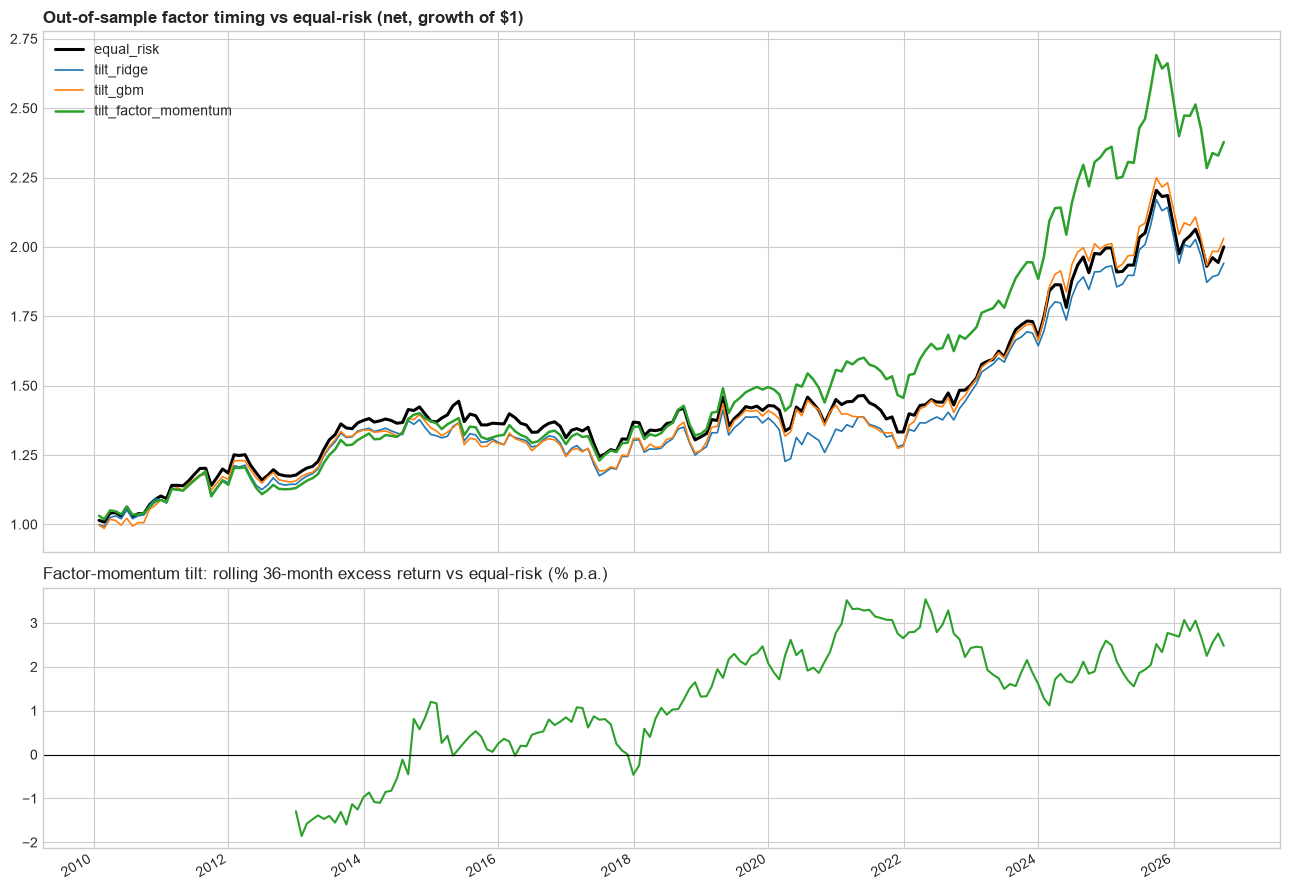

Live factor weights set at 2026-09-30 (for October 2026)
                  equal_risk_%  factor_momentum_tilt_%  momentum_score
tsmom_12                 29.24                   35.07            0.20
value                    18.81                   26.03            0.32
skewness                 14.96                   15.19           -0.13
mom_12_1                 12.71                   10.55           -0.30
carry                    10.65                    6.88           -0.44
hedging_pressure         13.63                    6.29           -1.01 

Saved: 07_timing_performance, 07_timing_vs_equal_risk, 07_prediction_quality, live weights (reports/tables); timing predictions and returns (data/processed)


In [8]:
# ============================================================
# 07 · Cell 8 — Charts, live weights and save
# ============================================================
TABLES_DIR = PATHS.root / "reports" / "tables"

fig, (ax_cum, ax_rel) = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                                     gridspec_kw={"height_ratios": [2, 1]})

# 1. Cumulative out-of-sample net returns
styles = {"equal_risk": {"color": "black", "lw": 2.2}, "tilt_ridge": {"lw": 1.2},
          "tilt_gbm": {"lw": 1.2}, "tilt_factor_momentum": {"lw": 1.8}}
for name, style in styles.items():
    (1 + net[name]).cumprod().plot(ax=ax_cum, label=name, **style)
ax_cum.set_title("Out-of-sample factor timing vs equal-risk (net, growth of $1)", loc="left",
                 fontweight="bold")
ax_cum.legend(loc="upper left")

# 2. Rolling 36-month excess return of the factor-momentum tilt
excess = net["tilt_factor_momentum"] - net["equal_risk"]
(excess.rolling(36).mean() * 1200).plot(ax=ax_rel, color="tab:green", lw=1.5)
ax_rel.axhline(0, color="black", lw=0.8)
ax_rel.set_title("Factor-momentum tilt: rolling 36-month excess return vs equal-risk (% p.a.)",
                 loc="left")
ax_rel.set_xlabel("")
fig.tight_layout()
fig.savefig(PATHS.figures / "07_factor_timing_oos.png", dpi=150)
plt.show()

# 3. Live weights for the next month (decision at the last available month-end)
live_date = predictions.index.get_level_values("date").max()
live = pd.DataFrame(
    {
        "equal_risk_%": weights["equal_risk"].loc[live_date] * 100,
        "factor_momentum_tilt_%": weights["tilt_factor_momentum"].loc[live_date] * 100,
        "momentum_score": predictions["factor_momentum"].xs(live_date, level="date"),
    }
).round(2)
print(f"Live factor weights set at {live_date:%Y-%m-%d} (for {live_date + pd.offsets.MonthEnd(1):%B %Y})")
print(live.sort_values("factor_momentum_tilt_%", ascending=False).to_string(), "\n")

# 4. Save
table.to_csv(TABLES_DIR / "07_timing_performance.csv")
pd.DataFrame(improvement).T.to_csv(TABLES_DIR / "07_timing_vs_equal_risk.csv")
results.to_csv(TABLES_DIR / "07_prediction_quality.csv")
predictions.to_parquet(PATHS.processed / "timing_predictions.parquet")
net.to_parquet(PATHS.processed / "timing_portfolio_returns.parquet")
live.to_csv(TABLES_DIR / f"07_live_weights_{live_date:%Y_%m}.csv")
print("Saved: 07_timing_performance, 07_timing_vs_equal_risk, 07_prediction_quality, "
      "live weights (reports/tables); timing predictions and returns (data/processed)")

In [9]:
# ============================================================
# 07 · Cell 9 — Top-k factor selection (Option A)
# ============================================================
def top_k_weights(prediction: pd.Series, k: int) -> pd.DataFrame:
    """Equal-risk weights among the k factors ranked highest each month; zero for the rest."""
    wide = prediction.unstack("factor").reindex(columns=FACTORS)
    rank = wide.rank(axis=1, ascending=False, method="first")
    base = portfolio.base_weights().reindex(wide.index)
    selected = base.where(rank <= k)
    return selected.div(selected.sum(axis=1), axis=0).fillna(0.0)


selection_net, selection_rows = {}, {}
for name in ["ridge", "gbm", "factor_momentum"]:
    for k in [2, 3]:
        label = f"top{k}_{name}"
        p = portfolio.performance(top_k_weights(predictions[name], k))
        r = p["net"].reindex(net.index)
        diff = r - net["equal_risk"]
        wealth = (1 + r).cumprod()
        selection_net[label] = r
        selection_rows[label] = {
            "ann_return_%": r.mean() * 1200,
            "ann_vol_%": r.std() * np.sqrt(12) * 100,
            "sharpe": r.mean() / r.std() * np.sqrt(12),
            "max_dd_%": (wealth / wealth.cummax() - 1).min() * 100,
            "turnover_pa": p["turnover"].mean() * 12,
            "excess_vs_equal_risk_%": diff.mean() * 1200,
            "excess_t_nw": newey_west_tstat(diff),
        }

er = net["equal_risk"]
er_wealth = (1 + er).cumprod()
selection_rows["equal_risk (all six)"] = {
    "ann_return_%": er.mean() * 1200, "ann_vol_%": er.std() * np.sqrt(12) * 100,
    "sharpe": er.mean() / er.std() * np.sqrt(12),
    "max_dd_%": (er_wealth / er_wealth.cummax() - 1).min() * 100,
    "turnover_pa": perf["equal_risk"]["turnover"].mean() * 12,
    "excess_vs_equal_risk_%": 0.0, "excess_t_nw": np.nan,
}
selection_table = pd.DataFrame(selection_rows).T
print("Top-k factor selection vs equal-risk (out of sample from 2010, net of costs)")
print(selection_table.round(2).to_string(), "\n")

selection_net = pd.DataFrame(selection_net)
selection_net["equal_risk (all six)"] = er
sub = pd.DataFrame(
    {label: selection_net.loc[a:b].apply(lambda r: r.mean() / r.std() * np.sqrt(12))
     for label, (a, b) in halves.items()}
)
print("Sharpe ratio by subperiod")
print(sub.round(2).to_string())

selection_table.to_csv(TABLES_DIR / "07_top_k_selection.csv")
print("\nSaved 07_top_k_selection.csv")

Top-k factor selection vs equal-risk (out of sample from 2010, net of costs)
                      ann_return_%  ann_vol_%  sharpe  max_dd_%  turnover_pa  excess_vs_equal_risk_%  excess_t_nw
top2_ridge                    5.04      11.31    0.45    -22.78         4.13                    0.53         0.28
top3_ridge                    3.89       9.91    0.39    -24.34         2.49                   -0.62        -0.40
top2_gbm                      5.02      11.75    0.43    -23.53        11.08                    0.52         0.25
top3_gbm                      4.59      10.07    0.46    -23.63         7.88                    0.08         0.05
top2_factor_momentum          7.23      11.49    0.63    -18.78         3.93                    2.72         1.35
top3_factor_momentum          7.06      10.14    0.70    -18.48         3.33                    2.56         1.94
equal_risk (all six)          4.51       8.26    0.55    -13.81         0.24                    0.00          NaN 

Sharpe ra